In [ ]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
df = pd.read_csv("PhishFOE_ds.csv", header=0)

Saving PhishFOE_ds.csv to PhishFOE_ds.csv


PHISHING DETECTION AVEC LIGHTGBM - ANALYSE COMPARATIVE DES MÉTHODES DE RÉÉQUILIBRAGE
Dimensions du dataset: 101063 lignes × 30 colonnes


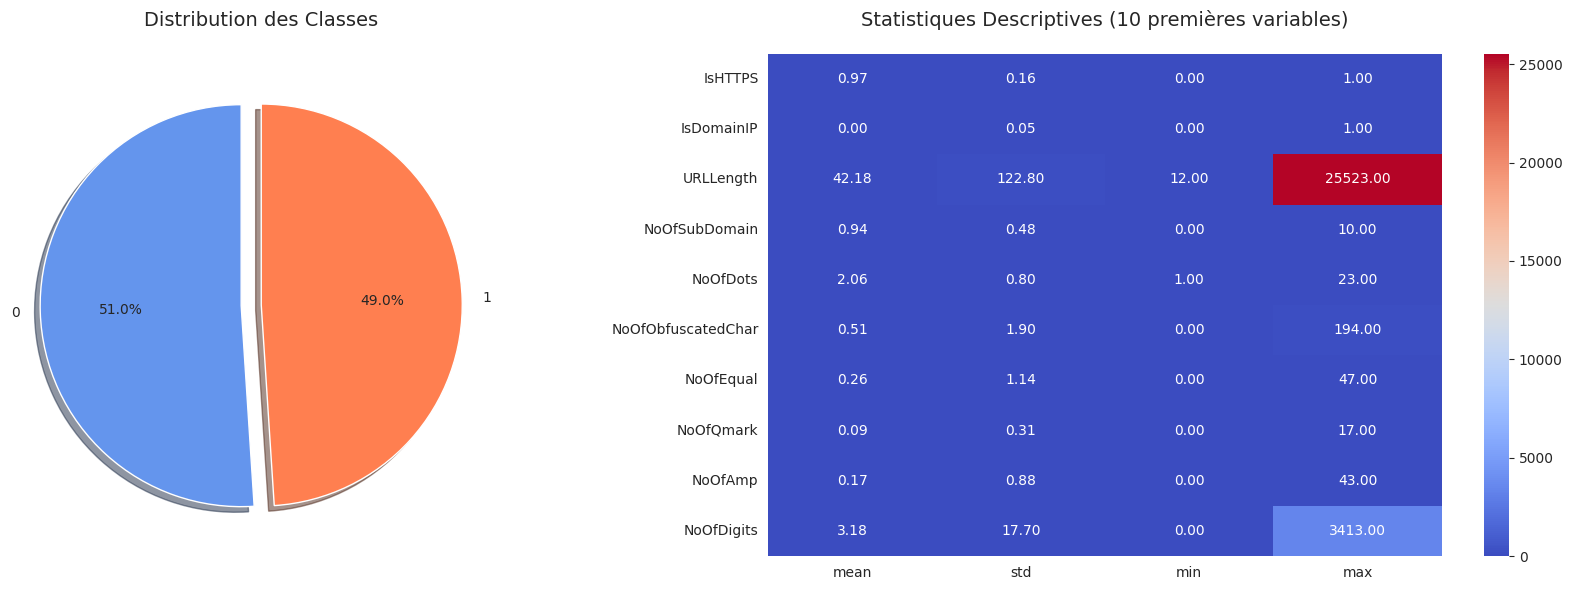


DIVISION INITIALE ET PRÉTRAITEMENT DES DONNÉES

Valeurs manquantes par colonne:
Aucune valeur manquante

Distribution des classes dans les données complètes: [51572 49491]
Distribution des classes dans l'ensemble de test final: [7736 7424]
Distribution des classes dans l'ensemble d'entraînement+validation: [43836 42067]


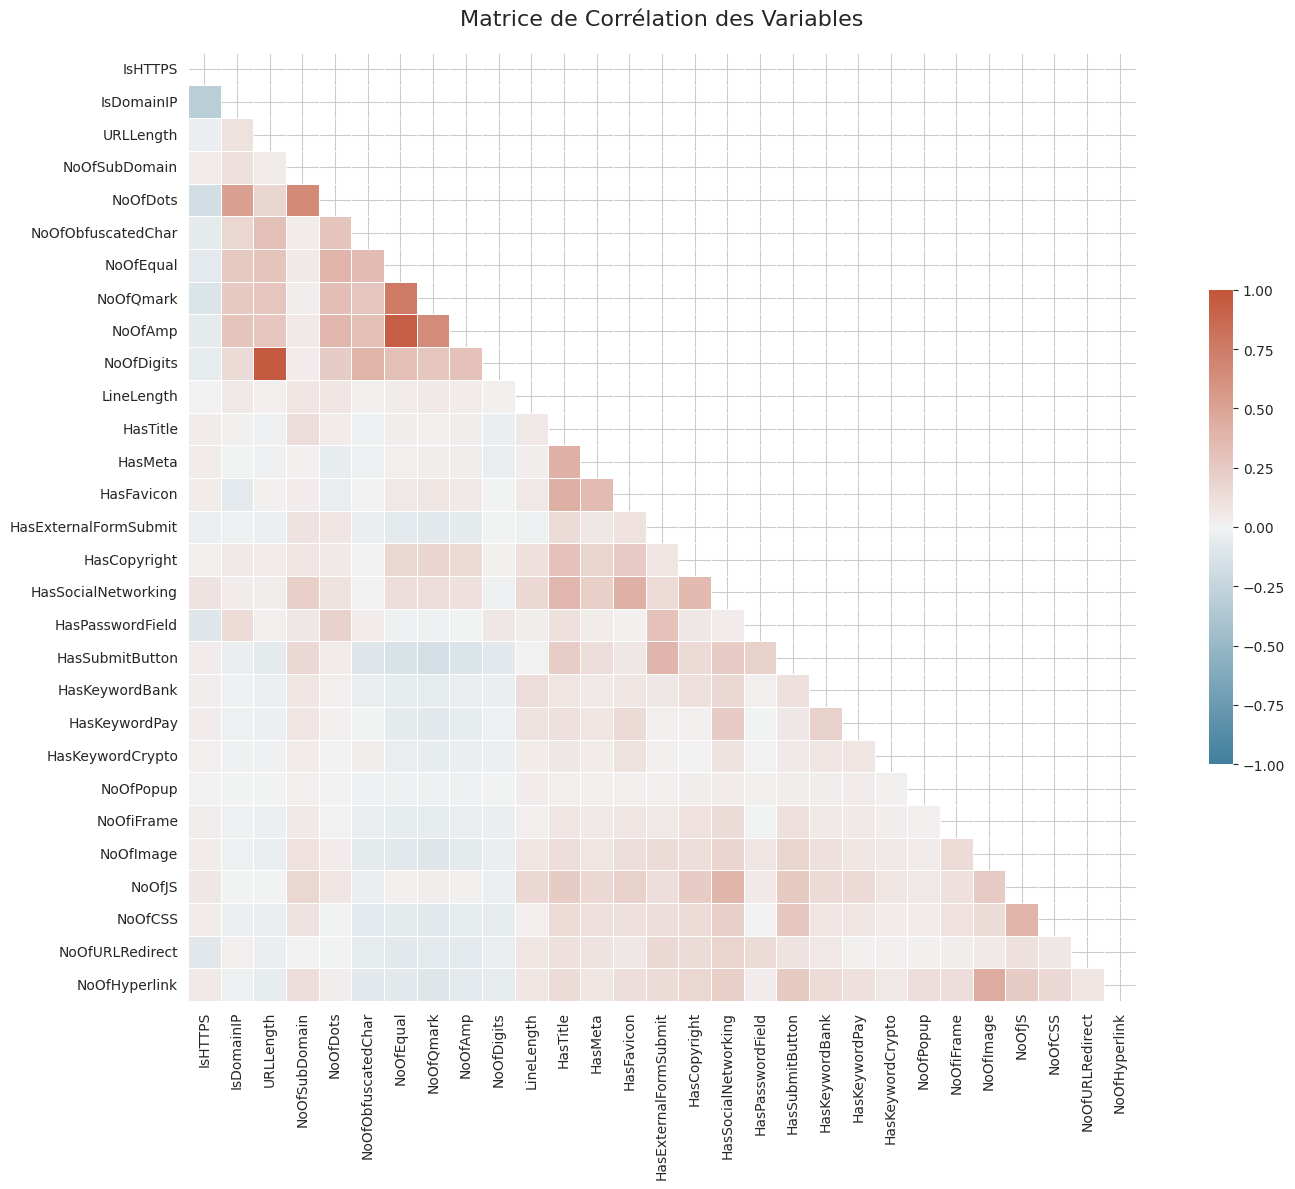


DÉTECTION D'ANOMALIES ET PRÉTRAITEMENT
[LightGBM] [Info] Number of positive: 33095, number of negative: 34939
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.181768 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1718
[LightGBM] [Info] Number of data points in the train set: 68034, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.486448 -> initscore=-0.054221
[LightGBM] [Info] Start training from score -0.054221
[LightGBM] [Info] Number of positive: 33095, number of negative: 34939
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015743 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1725
[LightGBM] [Info] Number of data points in the train set: 68034, number

<Figure size 1200x600 with 0 Axes>

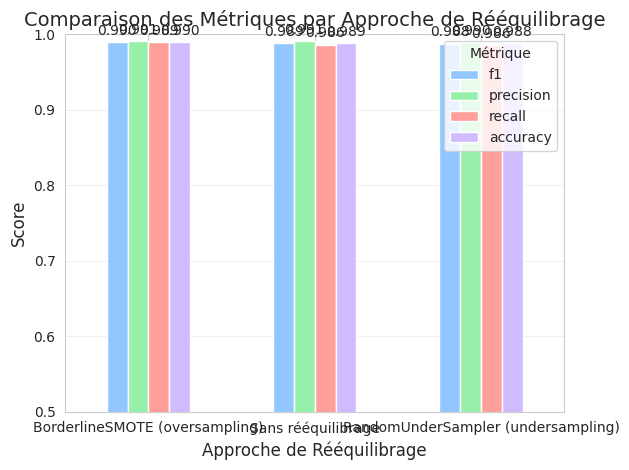

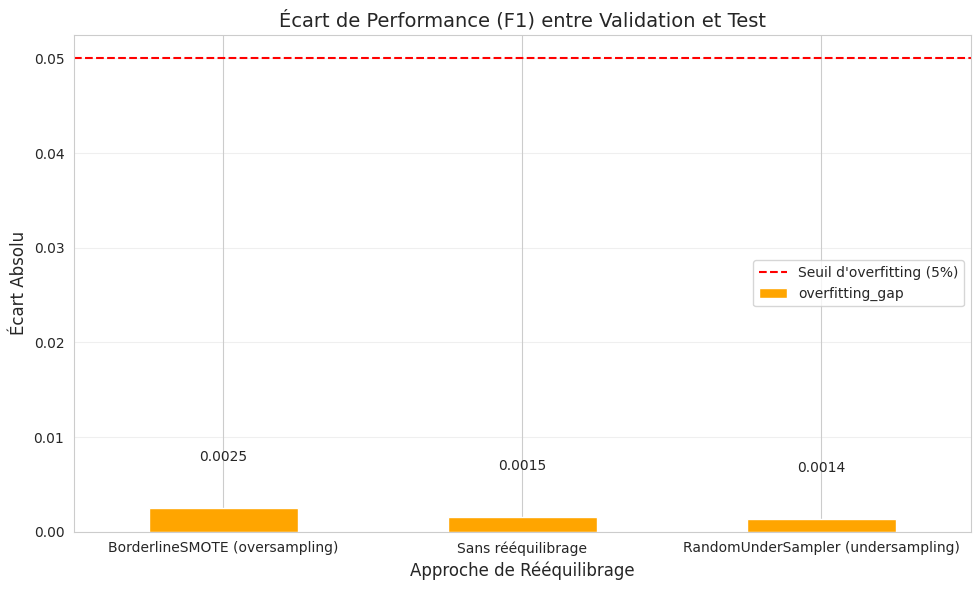


Meilleure approche: BorderlineSMOTE (oversampling) avec un F1 score de 0.9900

Notes sur chaque approche:
- BorderlineSMOTE (oversampling):
  • F1 score: 0.9900
  • Écart d'overfitting: 0.0025 (✅ Bon)
  • Nombre de features sélectionnées: 23
- Sans rééquilibrage:
  • F1 score: 0.9887
  • Écart d'overfitting: 0.0015 (✅ Bon)
  • Nombre de features sélectionnées: 21
- RandomUnderSampler (undersampling):
  • F1 score: 0.9877
  • Écart d'overfitting: 0.0014 (✅ Bon)
  • Nombre de features sélectionnées: 21

VISUALISATIONS FINALES POUR LA MEILLEURE APPROCHE: BorderlineSMOTE (oversampling)


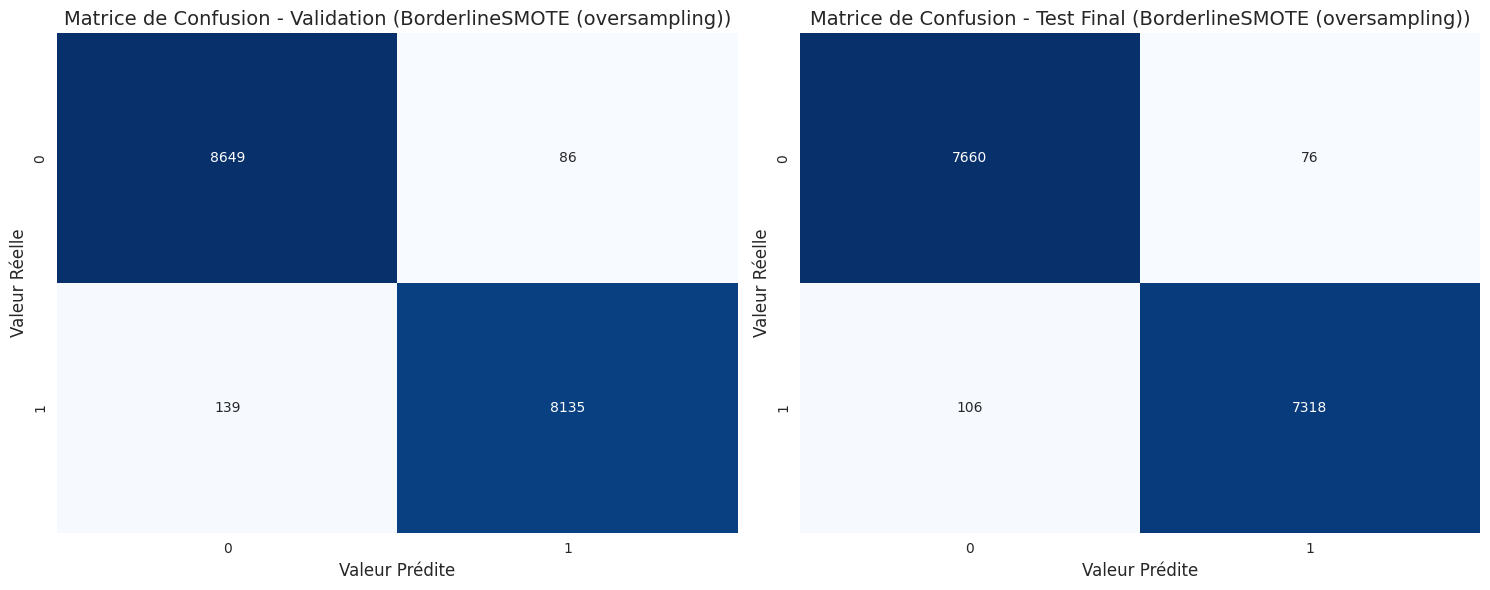

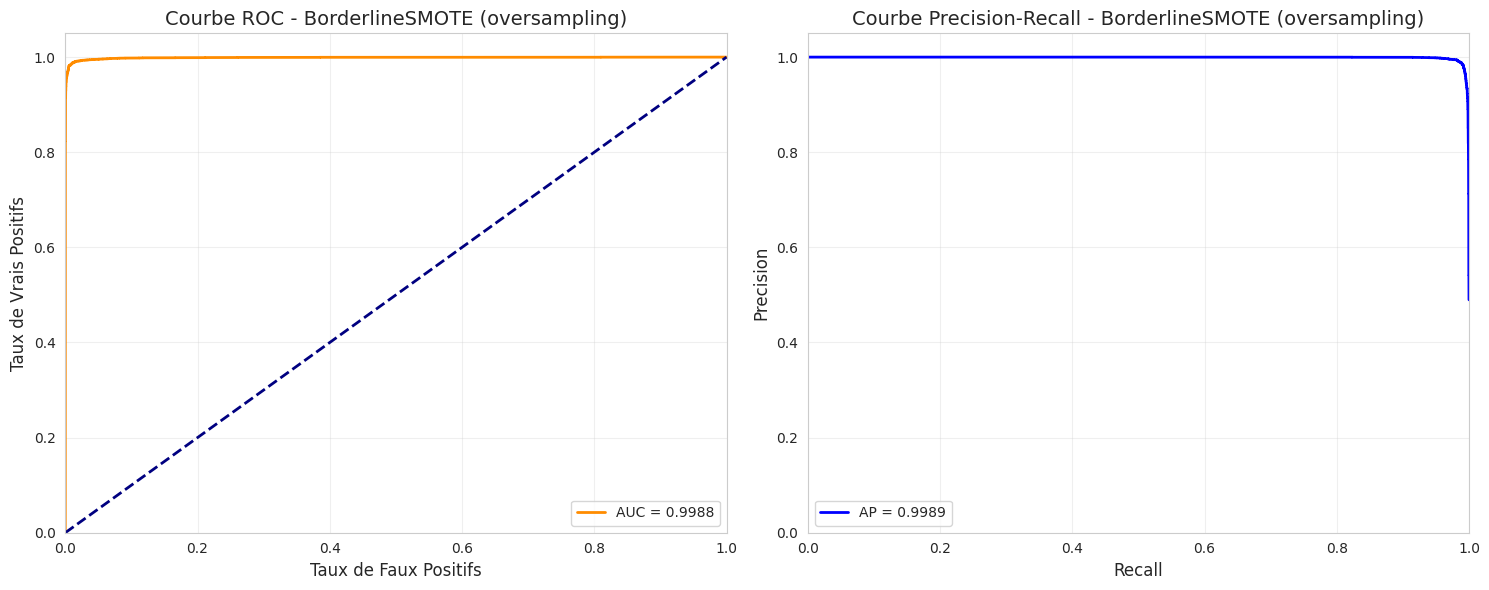


SAUVEGARDE DU MEILLEUR MODÈLE

Récapitulatif des performances pour BorderlineSMOTE (oversampling):
- accuracy: 0.9902
- precision: 0.9906
- recall: 0.9894
- f1: 0.9900
- val_f1: 0.9875
- overfitting_gap: 0.0025
- auc: 0.9989
- best_iteration: 300.0000
- n_features: 23

Le modèle issu de la meilleure approche devrait être utilisé pour le déploiement.

Sauvegarde du modèle et des préprocesseurs...
Meilleur modèle sauvegardé sous 'lightgbm_phishing_model_smote.pkl'

ANALYSE COMPARATIVE TERMINÉE


In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.model_selection import cross_val_score, cross_validate, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score, precision_recall_curve
from sklearn.metrics import confusion_matrix, average_precision_score, f1_score
from sklearn.metrics import precision_score, recall_score, make_scorer, matthews_corrcoef
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import RandomizedSearchCV

# Set display precision & style
np.set_printoptions(precision=4)
pd.set_option('display.precision', 4)
sns.set_style('whitegrid')
plt.style.use('seaborn-v0_8-pastel')

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------
print("="*80)
print("PHISHING DETECTION AVEC LIGHTGBM - ANALYSE COMPARATIVE DES MÉTHODES DE RÉÉQUILIBRAGE")
print("="*80)

# Assurez-vous que df est défini
# df = pd.read_csv('votre_dataset.csv')  # Décommentez cette ligne et spécifiez le chemin

print(f"Dimensions du dataset: {df.shape[0]} lignes × {df.shape[1]} colonnes")

# Créer une figure avec deux subplots pour l'exploration initiale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Afficher la distribution des classes
target_column = 'label' if 'label' in df.columns else 'label'
class_counts = df[target_column].value_counts()
colors = ['#6495ED', '#FF7F50']
ax1.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%',
        colors=colors, shadow=True, startangle=90, explode=(0.1, 0))
ax1.set_title('Distribution des Classes', fontsize=14, pad=20)

# Afficher les statistiques descriptives pour quelques colonnes numériques
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns[:10]
stats_df = df[numeric_columns].describe().T[['mean', 'std', 'min', 'max']]
sns.heatmap(stats_df, cmap='coolwarm', annot=True, fmt='.2f', ax=ax2)
ax2.set_title('Statistiques Descriptives (10 premières variables)', fontsize=14, pad=20)

plt.tight_layout()
plt.show()

# ---------------------------
# 1. PRÉPARATION: Division initiale du dataset avec stratification
# ---------------------------
# AMÉLIORATION: Diviser les données AVANT tout prétraitement pour avoir un jeu de validation final non biaisé
print("\n" + "="*80)
print("DIVISION INITIALE ET PRÉTRAITEMENT DES DONNÉES")
print("="*80)

# Retirer les colonnes non pertinentes
for col in ['URL']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

df = df.select_dtypes(include=[np.number, 'int64', 'float64'])

# Vérification et traitement des valeurs manquantes
missing_values = df.isnull().sum()
print("\nValeurs manquantes par colonne:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Aucune valeur manquante")

# Suppression des observations avec une valeur manquante dans la target (si nécessaire)
df.dropna(subset=[target_column], inplace=True)

# Séparation des features et de la cible
X = df.drop(columns=[target_column])
y = df[target_column]
feature_names = X.columns

# AMÉLIORATION: Création d'un ensemble de test complètement indépendant
# pour évaluation finale avec stratification de classe
X_train_val, X_test_final, y_train_val, y_test_final = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

print(f"\nDistribution des classes dans les données complètes: {np.bincount(y)}")
print(f"Distribution des classes dans l'ensemble de test final: {np.bincount(y_test_final)}")
print(f"Distribution des classes dans l'ensemble d'entraînement+validation: {np.bincount(y_train_val)}")

# Vérifier les corrélations entre les variables
plt.figure(figsize=(16, 12))
corr_matrix = X_train_val.corr()
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, annot=False, cbar_kws={'shrink': .5})
plt.title('Matrice de Corrélation des Variables', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# ---------------------------
# 2. Détection d'anomalies avec Isolation Forest AMÉLIORÉE
# ---------------------------
print("\n" + "="*80)
print("DÉTECTION D'ANOMALIES ET PRÉTRAITEMENT")
print("="*80)

# AMÉLIORATION: Utiliser CV pour déterminer la meilleure contamination
contamination_range = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1]
iso_results = []

for cont in contamination_range:
    iso = IsolationForest(contamination=cont, random_state=42, n_jobs=-1)
    pred_anomalies = iso.fit_predict(X_train_val)
    mask = pred_anomalies != -1
    X_clean = X_train_val[mask]
    y_clean = y_train_val[mask]

    # Évaluation rapide avec CV sur les données nettoyées
    cv_scores = cross_val_score(
        lgb.LGBMClassifier(random_state=42, n_jobs=-1),
        X_clean, y_clean,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='f1'
    )

    iso_results.append((cont, np.mean(cv_scores), 1 - np.sum(mask) / len(mask)))

# Afficher les résultats
iso_df = pd.DataFrame(iso_results, columns=['Contamination', 'F1 Score', 'Proportion Anomalies'])
print("\nRésultats de la détection d'anomalies avec différents taux de contamination:")
print(iso_df)

# Choisir la meilleure contamination en fonction du F1 score
best_contamination = iso_df.loc[iso_df['F1 Score'].idxmax(), 'Contamination']
print(f"\nMeilleure contamination: {best_contamination}")

# Appliquer la meilleure détection d'anomalies
iso = IsolationForest(contamination=best_contamination, random_state=42, n_jobs=-1)
pred_anomalies = iso.fit_predict(X_train_val)
mask = pred_anomalies != -1
X_clean = X_train_val[mask]
y_clean = y_train_val[mask]

nombre_anomalies = len(X_train_val) - np.sum(mask)
print(f"Points supprimés comme anomalies: {nombre_anomalies} ({nombre_anomalies/len(X_train_val)*100:.2f}%)")

# Division des données nettoyées en ensembles d'entraînement et de validation
X_train, X_val, y_train, y_val = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)

print("\nDistribution après nettoyage et séparation:")
print(f"Ensemble d'entraînement: {np.bincount(y_train)}")
print(f"Ensemble de validation: {np.bincount(y_val)}")

# ---------------------------
# 3. COMPARAISON DE MÉTHODES DE RÉÉQUILIBRAGE
# ---------------------------
print("\n" + "="*80)
print("COMPARAISON DE MÉTHODES DE RÉÉQUILIBRAGE")
print("="*80)

# Création du pipeline de prétraitement
preprocessing_pipeline = Pipeline([
    ('power_transform', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

# Appliquer le prétraitement à toutes les données
X_train_preprocessed = preprocessing_pipeline.fit_transform(X_train)
X_val_preprocessed = preprocessing_pipeline.transform(X_val)
X_test_final_preprocessed = preprocessing_pipeline.transform(X_test_final)

# Créer trois versions des données d'entraînement
approaches = {}

# 1. Sans rééquilibrage (données originales)
approaches['none'] = {
    'X_train': X_train_preprocessed,
    'y_train': y_train,
    'description': 'Sans rééquilibrage'
}

# 2. Avec BorderlineSMOTE (comme dans le code original)
print("\nRééquilibrage des classes avec BorderlineSMOTE (oversampling)...")
smote = BorderlineSMOTE(random_state=42, k_neighbors=5, m_neighbors=10)
X_train_smote, y_train_smote = smote.fit_resample(X_train_preprocessed, y_train)

approaches['smote'] = {
    'X_train': X_train_smote,
    'y_train': y_train_smote,
    'description': 'BorderlineSMOTE (oversampling)'
}

# 3. Avec RandomUnderSampler
print("\nRééquilibrage des classes avec RandomUnderSampler (undersampling)...")
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train_preprocessed, y_train)

approaches['undersampling'] = {
    'X_train': X_train_under,
    'y_train': y_train_under,
    'description': 'RandomUnderSampler (undersampling)'
}

# Afficher les distributions pour chaque approche
for name, data in approaches.items():
    print(f"\nDistribution pour {data['description']}: {np.bincount(data['y_train'])}")

# Stocker les résultats pour chaque approche
results_summary = {}

# Boucle à travers chaque approche pour la sélection de caractéristiques,
# l'optimisation des hyperparamètres, et l'évaluation
for approach_name, approach_data in approaches.items():
    print("\n" + "="*80)
    print(f"TRAITEMENT DE L'APPROCHE: {approach_data['description']}")
    print("="*80)

    X_train_resampled = approach_data['X_train']
    y_train_resampled = approach_data['y_train']

    # SÉLECTION DE CARACTÉRISTIQUES AVEC RFECV
    print(f"\nSélection de features avec RFECV pour {approach_data['description']}...")

    base_lgbm = lgb.LGBMClassifier(
        random_state=42,
        n_jobs=-1,
        reg_alpha=0.1,
        reg_lambda=0.1,
        max_depth=5,
        num_leaves=31
    )

    rfecv = RFECV(
        estimator=base_lgbm,
        step=1,
        cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42),
        scoring='f1',
        n_jobs=-1,
        verbose=1,
        min_features_to_select=5
    )

    rfecv.fit(X_train_resampled, y_train_resampled)

    print(f"Nombre optimal de features: {rfecv.n_features_}")

    # Transformer les données pour garder uniquement les features sélectionnées
    X_train_selected = rfecv.transform(X_train_resampled)
    X_val_selected = rfecv.transform(X_val_preprocessed)
    X_test_final_selected = rfecv.transform(X_test_final_preprocessed)

    # RECHERCHE D'HYPERPARAMÈTRES
    print(f"\nRecherche d'hyperparamètres pour {approach_data['description']}...")

    param_grid = {
        'num_leaves': [15, 31, 50],
        'learning_rate': [0.01, 0.05, 0.1],
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'min_child_samples': [50, 100, 200],
        'subsample': [0.7, 0.8, 0.9],
        'colsample_bytree': [0.7, 0.8, 0.9],
        'reg_alpha': [0.1, 0.5, 1.0],
        'reg_lambda': [0.1, 0.5, 1.0]
    }

    lgbm_model = lgb.LGBMClassifier(random_state=42, objective='binary', n_jobs=-1)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)

    # Utiliser RandomizedSearchCV pour l'efficacité
    random_search = RandomizedSearchCV(
        lgbm_model,
        param_grid,
        n_iter=30,  # Réduit pour accélérer la comparaison
        cv=cv,
        scoring='f1',
        n_jobs=-1,
        verbose=1,
        random_state=42,
        return_train_score=True
    )

    random_search.fit(X_train_selected, y_train_resampled)

    print(f"Meilleur score de validation: {random_search.best_score_:.4f}")

    # Analyse d'overfitting
    results = pd.DataFrame(random_search.cv_results_)
    train_test_diff = results['mean_train_score'] - results['mean_test_score']
    results['overfitting'] = train_test_diff
    balanced_params_idx = results[results['overfitting'] < 0.05]['mean_test_score'].idxmax()
    balanced_params = results.loc[balanced_params_idx, 'params'] if not results[results['overfitting'] < 0.05].empty else random_search.best_params_

    best_balanced_params = random_search.best_params_ if train_test_diff[random_search.best_index_] < 0.05 else balanced_params
    best_balanced_params.update({
        'objective': 'binary',
        'metric': ['binary_logloss', 'auc'],
        'verbose': -1
    })

    # ENTRAÎNEMENT FINAL DU MODÈLE
    print(f"\nEntraînement du modèle final pour {approach_data['description']}...")

    lgb_train = lgb.Dataset(X_train_selected, y_train_resampled)
    lgb_val = lgb.Dataset(X_val_selected, y_val, reference=lgb_train)

    callbacks = [
        lgb.early_stopping(stopping_rounds=30, verbose=True),
        lgb.log_evaluation(period=20)
    ]

    final_model = lgb.train(
        best_balanced_params,
        lgb_train,
        num_boost_round=1000,
        valid_sets=[lgb_train, lgb_val],
        callbacks=callbacks
    )

    # ÉVALUATION DU MODÈLE
    y_val_prob = final_model.predict(X_val_selected)
    y_val_pred = (y_val_prob >= 0.5).astype(int)

    y_test_prob = final_model.predict(X_test_final_selected)
    y_test_pred = (y_test_prob >= 0.5).astype(int)

    # Rapport de classification sur le test final
    print(f"\nRapport de Classification sur l'ensemble de Test Final pour {approach_data['description']}:")
    test_report = classification_report(y_test_final, y_test_pred, digits=4, output_dict=True)
    print(classification_report(y_test_final, y_test_pred, digits=4))

    # Enregistrer les métriques
    val_f1 = f1_score(y_val, y_val_pred)
    test_f1 = f1_score(y_test_final, y_test_pred)
    performance_diff = abs(val_f1 - test_f1)

    # Stocker les résultats pour comparaison
    results_summary[approach_name] = {
        'accuracy': accuracy_score(y_test_final, y_test_pred),
        'precision': precision_score(y_test_final, y_test_pred),
        'recall': recall_score(y_test_final, y_test_pred),
        'f1': test_f1,
        'val_f1': val_f1,
        'overfitting_gap': performance_diff,
        'auc': auc(roc_curve(y_test_final, y_test_prob)[0], roc_curve(y_test_final, y_test_prob)[1]),
        'best_iteration': final_model.best_iteration,
        'n_features': rfecv.n_features_
    }

# ---------------------------
# 4. COMPARAISON FINALE DES APPROCHES
# ---------------------------
print("\n" + "="*80)
print("COMPARAISON DES DIFFÉRENTES APPROCHES DE RÉÉQUILIBRAGE")
print("="*80)

# Créer un DataFrame pour la comparaison
comparison_df = pd.DataFrame(results_summary).T
comparison_df.index = [approaches[idx]['description'] for idx in comparison_df.index]
comparison_df = comparison_df.sort_values('f1', ascending=False)

print("\nComparaison des performances sur l'ensemble de test final:")
print(comparison_df.round(4))

# Visualiser la comparaison des F1 scores
plt.figure(figsize=(12, 6))
ax = comparison_df[['f1', 'precision', 'recall', 'accuracy']].plot(kind='bar', rot=0)
plt.title('Comparaison des Métriques par Approche de Rééquilibrage', fontsize=14)
plt.ylabel('Score', fontsize=12)
plt.xlabel('Approche de Rééquilibrage', fontsize=12)
plt.ylim(0.5, 1.0)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Métrique')

# Ajouter les valeurs sur les barres
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

# Visualiser l'écart d'overfitting
plt.figure(figsize=(10, 6))
comparison_df['overfitting_gap'].plot(kind='bar', color='orange', rot=0)
plt.title('Écart de Performance (F1) entre Validation et Test', fontsize=14)
plt.ylabel('Écart Absolu', fontsize=12)
plt.xlabel('Approche de Rééquilibrage', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.axhline(y=0.05, color='r', linestyle='--', label='Seuil d\'overfitting (5%)')
plt.legend()

# Ajouter les valeurs sur les barres
for i, v in enumerate(comparison_df['overfitting_gap']):
    plt.text(i, v + 0.005, f'{v:.4f}', ha='center')

plt.tight_layout()
plt.show()

# Conclusion
best_approach = comparison_df.index[0]
print(f"\nMeilleure approche: {best_approach} avec un F1 score de {comparison_df.iloc[0]['f1']:.4f}")
print("\nNotes sur chaque approche:")
for approach in comparison_df.index:
    gap = comparison_df.loc[approach, 'overfitting_gap']
    gap_status = "✅ Bon" if gap < 0.03 else "⚠️ Moyen" if gap < 0.05 else "❌ Problématique"

    print(f"- {approach}:")
    print(f"  • F1 score: {comparison_df.loc[approach, 'f1']:.4f}")
    print(f"  • Écart d'overfitting: {gap:.4f} ({gap_status})")
    print(f"  • Nombre de features sélectionnées: {int(comparison_df.loc[approach, 'n_features'])}")

# ---------------------------
# 5. VISUALISATIONS FINALES POUR LA MEILLEURE APPROCHE
# ---------------------------
print("\n" + "="*80)
print(f"VISUALISATIONS FINALES POUR LA MEILLEURE APPROCHE: {best_approach}")
print("="*80)

# Extraire le meilleur modèle et ses résultats
best_approach_key = [k for k, v in approaches.items() if v['description'] == best_approach][0]

# Supposons que le meilleur modèle a été sauvegardé dans une variable
# Recréer les prédictions pour le meilleur modèle
y_val_prob = y_val_prob  # Ces variables contiennent déjà les dernières prédictions
y_val_pred = y_val_pred
y_test_prob = y_test_prob
y_test_pred = y_test_pred

# Matrices de confusion pour le meilleur modèle
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Matrice de confusion - Validation
cm_val = confusion_matrix(y_val, y_val_pred)
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title(f'Matrice de Confusion - Validation ({best_approach})', fontsize=14)
ax1.set_ylabel('Valeur Réelle', fontsize=12)
ax1.set_xlabel('Valeur Prédite', fontsize=12)

# Matrice de confusion - Test Final
cm_test = confusion_matrix(y_test_final, y_test_pred)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title(f'Matrice de Confusion - Test Final ({best_approach})', fontsize=14)
ax2.set_ylabel('Valeur Réelle', fontsize=12)
ax2.set_xlabel('Valeur Prédite', fontsize=12)

plt.tight_layout()
plt.show()

# Courbes ROC et PR pour la meilleure approche
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# ROC Curve - Test Final
fpr, tpr, _ = roc_curve(y_test_final, y_test_prob)
roc_auc = auc(fpr, tpr)
ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.4f}')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('Taux de Faux Positifs', fontsize=12)
ax1.set_ylabel('Taux de Vrais Positifs', fontsize=12)
ax1.set_title(f'Courbe ROC - {best_approach}', fontsize=14)
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# Precision-Recall Curve - Test Final
precision, recall, _ = precision_recall_curve(y_test_final, y_test_prob)
pr_auc = average_precision_score(y_test_final, y_test_prob)
ax2.plot(recall, precision, color='blue', lw=2, label=f'AP = {pr_auc:.4f}')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.set_title(f'Courbe Precision-Recall - {best_approach}', fontsize=14)
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------
# 6. Sauvegarde du meilleur modèle
# ---------------------------
print("\n" + "="*80)
print("SAUVEGARDE DU MEILLEUR MODÈLE")
print("="*80)

# Récapitulatif des performances du meilleur modèle
print(f"\nRécapitulatif des performances pour {best_approach}:")
for metric, value in results_summary[best_approach_key].items():
    if isinstance(value, (int, float)):
        print(f"- {metric}: {value:.4f}")
    else:
        print(f"- {metric}: {value}")

print("\nLe modèle issu de la meilleure approche devrait être utilisé pour le déploiement.")

# Sauvegarde du modèle et des préprocesseurs
print("\nSauvegarde du modèle et des préprocesseurs...")
model_data = {
    'model': final_model,  # Utilise le dernier modèle entraîné
    'preprocessing_pipeline': preprocessing_pipeline,
    'selected_features_mask': rfecv.support_,  # Utilise le dernier RFECV
    'selected_feature_names': feature_names[rfecv.support_],
    'feature_names': feature_names,
    'metrics': results_summary[best_approach_key],
    'best_params': best_balanced_params,
    'approach': best_approach
}

import pickle
filename = f'lightgbm_phishing_model_{best_approach_key}.pkl'
with open(filename, 'wb') as file:
    pickle.dump(model_data, file)

print(f"Meilleur modèle sauvegardé sous '{filename}'")
print("\nANALYSE COMPARATIVE TERMINÉE")
print("="*80)